<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<div style="border-bottom:1px solid rgba(148,163,184,0.35);padding-bottom:12px;margin-bottom:16px;">
<h1 style="text-align:right;margin-bottom:4px;color:inherit;">آزمایشگاه گراف و جست‌وجو</h1>
<p style="text-align:right;margin:2px 0;"><strong>المپیاد هوش مصنوعی — دبیرستان علامه حلی یک</strong></p>
</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;
            background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">این مجموعه تمرین دقیقاً دربارهٔ چیست؟</h3>

<p>در این سه زنگ قرار است یک سؤال ساده را بارها با روش‌های مختلف حل کنیم:</p>
<p style="text-align:center;font-size:1.05em;"><strong>«از نقطهٔ شروع <code>S</code> چگونه به هدف <code>G</code> برسیم؟»</strong></p>

<p>ابتدا یاد می‌گیریم مسئله را به شکل <strong>Graph / State Space</strong> ببینیم. سپس روش‌های مختلف جست‌وجو را روی همان ماز اجرا می‌کنیم.</p>

<p>ایدهٔ اصلی این نیست که کد چند الگوریتم را حفظ کنیم. تقریباً همهٔ الگوریتم‌های این جلسه یک سؤال مشترک دارند:</p>
<p style="text-align:center;"><strong>«از بین حالت‌هایی که پیدا کرده‌ایم، کدام حالت را زودتر بررسی کنیم؟»</strong></p>

<ul>
<li><strong>DFS:</strong> آخرین حالت اضافه‌شده را زودتر بررسی می‌کند.</li>
<li><strong>BFS:</strong> اولین حالت اضافه‌شده را زودتر بررسی می‌کند.</li>
<li><strong>DLS / IDS:</strong> عمق جست‌وجو را کنترل می‌کنند.</li>
<li><strong>UCS:</strong> حالت کم‌هزینه‌تر را زودتر بررسی می‌کند.</li>
<li><strong>Greedy:</strong> حالتی را ترجیح می‌دهد که ظاهراً به هدف نزدیک‌تر است.</li>
<li><strong>A*:</strong> هزینهٔ طی‌شده و تخمین فاصله تا هدف را با هم می‌بیند.</li>
</ul>

<p><strong>نکتهٔ مهم:</strong> در این تمرین، Stack، Queue و Priority Queue را ابتدا با پیاده‌سازی‌های ساده و قابل‌مشاهده بررسی می‌کنیم تا رفتار هر ساختار روشن باشد.</p>

</div>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #0ea5e9;
            background:rgba(14,165,233,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">قبل از شروع کد: نقشهٔ ذهنی Search</h3>

<p>قبل از اینکه وارد Graph یا Maze شویم، پنج واژه را از همین ابتدا داشته باش:</p>

<ul>
<li><strong>State:</strong> وضعیت فعلی مسئله؛ یعنی «الان کجا هستیم؟»</li>
<li><strong>Frontier:</strong> حالت‌هایی که پیدا کرده‌ایم و منتظرند بعداً بررسی شوند.</li>
<li><strong>Discovered:</strong> حالت‌هایی که قبلاً پیدا شده‌اند تا دوباره بی‌دلیل وارد Frontier نشوند.</li>
<li><strong>Parent:</strong> نشان می‌دهد برای رسیدن به یک State از کدام State قبلی آمده‌ایم.</li>
<li><strong>Expand:</strong> یک State را از Frontier برداریم و همسایه‌هایش را پیدا کنیم.</li>
</ul>

<p>تقریباً همهٔ الگوریتم‌های این جلسه این اسکلت را دارند:</p>

<pre style="direction:ltr;text-align:left;white-space:pre-wrap;color:inherit;">Start -> Frontier

while Frontier is not empty:
    choose one State
    if it is Goal:
        stop
    expand it
    add new States to Frontier</pre>

<p><strong>سؤال اصلی کل جلسه:</strong> از Frontier کدام State را باید زودتر انتخاب کنیم؟ تفاوت DFS، BFS، UCS، Greedy و A* تا حد زیادی از پاسخ متفاوت به همین سؤال می‌آید.</p>

</div>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۰: آماده‌سازی محیط و داده‌ها</h2>

<p>سلول بعدی چند تابع کمکی را آماده می‌کند. لازم نیست جزئیات همهٔ آن‌ها را حفظ کنید؛ فقط بدانید هرکدام چه کاری انجام می‌دهد:</p>

<ul>
<li><code>load_maze_csv</code>: ماز را از فایل CSV می‌خواند.</li>
<li><code>load_weighted_graph_json</code>: اطلاعات گراف وزن‌دار را از JSON می‌خواند.</li>
<li><code>measure_search</code>: زمان اجرای یک Search را اندازه می‌گیرد.</li>
<li><code>find_marker</code>: محل <code>S</code> یا <code>G</code> را در ماز پیدا می‌کند.</li>
<li><code>path_length</code>: تعداد حرکت‌های مسیر را حساب می‌کند.</li>
<li><code>make_result</code>: نتیجهٔ Search را در یک ساختار یکسان جمع می‌کند.</li>
<li><code>draw_maze</code>: ماز، خانه‌های بررسی‌شده و مسیر نهایی را رسم می‌کند.</li>
<li><code>draw_graph</code>: گراف ساده را رسم می‌کند.</li>
<li><code>draw_weighted_graph</code>: گراف وزن‌دار را همراه وزن یال‌ها رسم می‌کند.</li>
<li><code>show_result</code>: نتیجهٔ یک الگوریتم را چاپ و نمایش می‌دهد.</li>
<li><code>show_comparison_table</code>: نتیجهٔ چند الگوریتم را در یک جدول مقایسه می‌کند.</li>
</ul>

<p>بعداً هرجا به یکی از این توابع نیاز داشته باشیم، کاربردش را دوباره همان‌جا می‌بینیم.</p>

</div>

In [2]:
import csv
import json
import time

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, HTML


def load_maze_csv(filename):
    # Load a maze from a CSV file.
    maze = []

    with open(filename, 'r', encoding='utf-8') as file:
        reader = csv.reader(file)

        for row in reader:
            maze.append(row)

    return maze


def load_weighted_graph_json(filename):
    # Load weighted graph data from a JSON file.
    with open(filename, 'r', encoding='utf-8') as file:
        data = json.load(file)

    return data


def measure_search(search_function, data, start, goal):
    # Measure one complete search run in milliseconds.
    begin = time.perf_counter()
    result = search_function(data, start, goal)
    elapsed_ms = (time.perf_counter() - begin) * 1000

    if result is not None:
        result['elapsed_ms'] = elapsed_ms

    return result


def find_marker(maze, marker):
    # Find the coordinates of S or G.
    for r in range(len(maze)):
        for c in range(len(maze[0])):
            if maze[r][c] == marker:
                return (r, c)
    return None


def path_length(path):
    # Count edges in a path.
    if path == []:
        return None
    return len(path) - 1


def make_result(found, path, expanded, visited_order, status):
    # Store search output in a simple dictionary.
    result = {}
    result['found'] = found
    result['status'] = status
    result['path'] = path
    result['path_length'] = path_length(path)
    result['expanded'] = expanded
    result['visited_order'] = visited_order
    return result


def draw_maze(maze, path, visited, title):
    # Draw maze, explored cells, and final path.
    path_cells = set(path)
    visited_cells = set(visited)
    start = find_marker(maze, 'S')
    goal = find_marker(maze, 'G')
    grid = []

    for r in range(len(maze)):
        row_codes = []
        for c in range(len(maze[0])):
            position = (r, c)
            if maze[r][c] == '#':
                code_value = 0
            else:
                code_value = 1
            if position in visited_cells and maze[r][c] != '#':
                code_value = 2
            if position in path_cells:
                code_value = 3
            if position == start:
                code_value = 4
            if position == goal:
                code_value = 5
            row_codes.append(code_value)
        grid.append(row_codes)

    colors = ['#263238', '#f7f7f7', '#9ecae1', '#ffd166', '#4caf70', '#e85d5d']
    color_map = ListedColormap(colors)
    figure, axis = plt.subplots(figsize=(7, 4))
    axis.imshow(grid, cmap=color_map, vmin=0, vmax=5)
    rows = len(maze)
    cols = len(maze[0])
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_title(title)
    for r in range(rows + 1):
        axis.axhline(r - 0.5, linewidth=0.4, alpha=0.25)
    for c in range(cols + 1):
        axis.axvline(c - 0.5, linewidth=0.4, alpha=0.25)
    plt.show()


def draw_graph(edges, positions, title):
    # Draw a small graph from an edge list.
    figure, axis = plt.subplots(figsize=(6, 3.6))
    for edge in edges:
        u = edge[0]
        v = edge[1]
        x1 = positions[u][0]
        y1 = positions[u][1]
        x2 = positions[v][0]
        y2 = positions[v][1]
        axis.plot([x1, x2], [y1, y2], linewidth=1.5)
    for node in positions:
        x = positions[node][0]
        y = positions[node][1]
        axis.scatter([x], [y], s=650)
        axis.text(x, y, node, ha='center', va='center', fontsize=11)
    axis.set_title(title)
    axis.axis('off')
    plt.show()


def draw_weighted_graph(edges, positions, title):
    # Draw a small weighted graph.
    figure, axis = plt.subplots(figsize=(6.3, 3.8))
    for edge in edges:
        u = edge[0]
        v = edge[1]
        weight = edge[2]
        x1 = positions[u][0]
        y1 = positions[u][1]
        x2 = positions[v][0]
        y2 = positions[v][1]
        axis.plot([x1, x2], [y1, y2], linewidth=1.5)
        middle_x = (x1 + x2) / 2
        middle_y = (y1 + y2) / 2
        axis.text(middle_x, middle_y, str(weight), fontsize=10)
    for node in positions:
        x = positions[node][0]
        y = positions[node][1]
        axis.scatter([x], [y], s=650)
        axis.text(x, y, node, ha='center', va='center', fontsize=11)
    axis.set_title(title)
    axis.axis('off')
    plt.show()


def show_result(name, result, maze):
    # Print and draw one search result.
    if result is None:
        print(name, ': TODO')
        return
    print(name)
    print('found =', result['found'])
    print('path length =', result['path_length'])
    print('expanded =', result['expanded'])
    if 'elapsed_ms' in result:
        print('time =', round(result['elapsed_ms'], 4), 'ms')
    if maze is not None and result['found']:
        draw_maze(maze, result['path'], result['visited_order'], name)

def show_comparison_table(comparison):
    # Display search results as a styled HTML table.
    rows_html = ''

    for index in range(len(comparison)):
        name = comparison[index][0]
        result = comparison[index][1]

        if result['found']:
            found_text = 'Yes'
        else:
            found_text = 'No'

        if result['path_length'] is None:
            path_text = '-'
        else:
            path_text = str(result['path_length'])

        time_text = str(round(result['elapsed_ms'], 4))

        if index % 2 == 0:
            row_background = 'rgba(148, 163, 184, 0.06)'
        else:
            row_background = 'transparent'

        rows_html = rows_html + f"""
        <tr style="background:{row_background};">
            <td style="padding:10px 14px;border-bottom:1px solid rgba(148,163,184,0.22);font-weight:700;">{name}</td>
            <td style="padding:10px 14px;border-bottom:1px solid rgba(148,163,184,0.22);text-align:center;">{found_text}</td>
            <td style="padding:10px 14px;border-bottom:1px solid rgba(148,163,184,0.22);text-align:center;">{path_text}</td>
            <td style="padding:10px 14px;border-bottom:1px solid rgba(148,163,184,0.22);text-align:center;">{result['expanded']}</td>
            <td style="padding:10px 14px;border-bottom:1px solid rgba(148,163,184,0.22);text-align:center;font-family:monospace;">{time_text}</td>
        </tr>
        """

    html = f"""
    <div style="margin:14px 0 20px 0;overflow-x:auto;">
        <div style="font-weight:700;margin-bottom:8px;">Search Algorithms Comparison</div>
        <table style="
            width:100%;
            max-width:900px;
            border-collapse:separate;
            border-spacing:0;
            border:1px solid rgba(96,165,250,0.35);
            border-radius:10px;
            overflow:hidden;
            color:inherit;
        ">
            <thead>
                <tr style="background:rgba(37,99,235,0.16);">
                    <th style="padding:11px 14px;text-align:left;">Algorithm</th>
                    <th style="padding:11px 14px;text-align:center;">Found</th>
                    <th style="padding:11px 14px;text-align:center;">Path Length</th>
                    <th style="padding:11px 14px;text-align:center;">Expanded</th>
                    <th style="padding:11px 14px;text-align:center;">Time (ms)</th>
                </tr>
            </thead>
            <tbody>
                {rows_html}
            </tbody>
        </table>
        <div style="margin-top:7px;font-size:0.9em;opacity:0.78;">
            Time values can vary slightly between runs, especially on small mazes.
        </div>
    </div>
    """

    display(HTML(html))



<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">کدام تابع‌ها را باید واقعاً بفهمیم؟</h3>

<p>همهٔ تابع‌های سلول Setup اهمیت یکسان ندارند.</p>

<p><strong>برای حل تمرین‌ها باید منطق این‌ها را خوب بفهمی:</strong></p>
<ul>
<li><code>build_adjacency_list</code>: تبدیل یال‌ها به فهرست همسایه‌ها.</li>
<li><code>get_neighbors</code>: پیدا کردن حرکت‌های مجاز از State فعلی.</li>
<li><code>reconstruct_path</code>: ساخت مسیر نهایی با استفاده از <code>parent</code>.</li>
<li><code>pop_smallest</code>: انتخاب عضو با کمترین Priority.</li>
<li><code>manhattan_distance</code>: ساخت Heuristic برای Greedy و A*.</li>
<li>خود الگوریتم‌های DFS، BFS، DLS، IDS، UCS، Greedy و A*.</li>
</ul>

<p><strong>این سه تابع را در حد ورودی و خروجی بشناس:</strong></p>
<ul>
<li><code>make_result</code>: خروجی الگوریتم‌ها را یک‌شکل می‌کند.</li>
<li><code>measure_search</code>: زمان اجرای الگوریتم را اندازه می‌گیرد.</li>
<li><code>path_length</code>: تعداد حرکت‌های مسیر را حساب می‌کند.</li>
</ul>

<p><strong>بقیهٔ تابع‌ها ابزار کمکی‌اند:</strong> خواندن فایل، پیدا کردن S/G، رسم ماز و نمایش جدول. </p>

</div>
</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">🔎 تابع make_result دقیقاً چه کار می‌کند؟</h3>

<p><code>make_result</code> خودش الگوریتم جست‌وجو نیست. فقط نتیجهٔ DFS، BFS، A* و بقیه را با یک <strong>فرمت استاندارد</strong> برمی‌گرداند.</p>

<p>امضای تابع:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">make_result(found, path, expanded, visited_order, status)</pre>

<p>ورودی‌ها:</p>
<ul>
<li><code>found</code>: آیا Goal پیدا شده؟ <code>True</code> یا <code>False</code>.</li>
<li><code>path</code>: مسیر Start تا Goal؛ اگر جوابی نباشد معمولاً <code>[]</code>.</li>
<li><code>expanded</code>: چند State واقعاً بررسی شده است.</li>
<li><code>visited_order</code>: Stateها با چه ترتیبی بررسی شده‌اند؛ برای Visualization هم استفاده می‌شود.</li>
<li><code>status</code>: وضعیت جست‌وجو؛ مثل <code>success</code>، <code>failure</code> یا در DLS مقدار <code>cutoff</code>.</li>
</ul>

<p>مثلاً:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">return make_result(
    True,
    path,
    len(visited_order),
    visited_order,
    'success'
)</pre>

<p>خروجی تقریباً چنین Dictionaryای است:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">{
    'found': True,
    'status': 'success',
    'path': [...],
    'path_length': 14,
    'expanded': 29,
    'visited_order': [...]
}</pre>

<p><code>path_length</code> داخل همین تابع از روی مسیر محاسبه می‌شود. زمان اجرا هم بعداً توسط <code>measure_search</code> با کلید <code>elapsed_ms</code> به نتیجه اضافه می‌شود.</p>

<p><strong>چرا فقط <code>return path</code> نمی‌کنیم؟</strong><br>
چون در پایان علاوه بر خود مسیر، می‌خواهیم الگوریتم‌ها را از نظر پیدا شدن جواب، تعداد Stateهای بررسی‌شده، زمان و ترتیب جست‌وجو هم مقایسه کنیم.</p>

</div>
</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">⏱️ دو Helper کوچک که زیاد می‌بینیم</h3>

<p><code>path_length(path)</code>: اگر مسیر مثلاً ۶ خانه داشته باشد، ۵ حرکت دارد؛ بنابراین <code>len(path) - 1</code> را برمی‌گرداند.</p>

<p><code>measure_search(...)</code>: قبل از اجرای تابع جست‌وجو زمان را می‌گیرد، Search را اجرا می‌کند، بعد مدت اجرا را با واحد میلی‌ثانیه داخل <code>elapsed_ms</code> می‌گذارد.</p>

<p>این دو تابع رفتار DFS/BFS/A* را تغییر نمی‌دهند؛ فقط نتیجه را برای مقایسه آماده می‌کنند.</p>

</div>
</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۱: Graph و Adjacency List</h2>

<p>یک <strong>Graph</strong> از رأس‌ها و یال‌ها ساخته می‌شود:</p>
<ul>
<li><strong>Node / Vertex:</strong> یک شیء یا موقعیت؛ مثلاً یک بازیکن یا یک خانه.</li>
<li><strong>Edge:</strong> ارتباط بین دو رأس.</li>
<li><strong>Neighbor:</strong> رأسی که مستقیماً به رأس فعلی وصل است.</li>
<li><strong>Adjacency List:</strong> برای هر رأس، فهرست همسایه‌های آن را نگه می‌داریم.</li>
</ul>

<p>مثلاً اگر <code>A</code> به <code>B</code> و <code>C</code> وصل باشد:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">A : [B, C]</pre>

<p>در این مثال گراف <strong>بدون جهت</strong> است؛ پس اگر <code>A</code> به <code>B</code> وصل باشد، <code>B</code> نیز به <code>A</code> وصل است.</p>

</div>

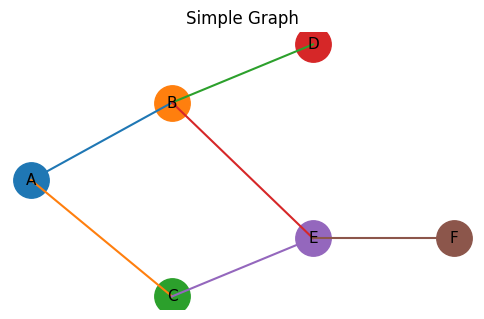

In [3]:
edges = [
    ('A', 'B'),
    ('A', 'C'),
    ('B', 'D'),
    ('B', 'E'),
    ('C', 'E'),
    ('E', 'F')
]

positions = {
    'A': (0, 1),
    'B': (1, 1.4),
    'C': (1, 0.4),
    'D': (2, 1.7),
    'E': (2, 0.7),
    'F': (3, 0.7)
}

draw_graph(edges, positions, 'Simple Graph')


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<h3 style="text-align:right;color:inherit;">تمرین ۱: ساخت Adjacency List</h3>
</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">ورودی و خروجی این تمرین</h3>

<p><code>build_adjacency_list(edges)</code></p>
<ul>
<li><strong>ورودی:</strong> لیستی از یال‌ها؛ مثل <code>('A', 'B')</code>.</li>
<li><strong>خروجی:</strong> Dictionaryای که برای هر رأس، لیست همسایه‌هایش را نگه می‌دارد.</li>
</ul>
<pre style="direction:ltr;text-align:left;color:inherit;">[('A','B'), ('A','C')]
        ↓
{'A': ['B','C'], 'B': ['A'], 'C': ['A']}</pre>

</div>
</div>

In [4]:
def build_adjacency_list(edges):
    graph = {}

    for u, v in edges:
        if u not in graph:
            graph[u] = []

        if v not in graph:
            graph[v] = []

        graph[u].append(v)
        graph[v].append(u)

    return graph



graph = build_adjacency_list(edges)

if 'A' in graph and 'E' in graph:
    print('Adjacency list looks ready:', graph)
else:
    print('TODO: complete build_adjacency_list')


Adjacency list looks ready: {'A': ['B', 'C'], 'B': ['A', 'D', 'E'], 'C': ['A', 'E'], 'D': ['B'], 'E': ['B', 'C', 'F'], 'F': ['E']}


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۲: تبدیل ماز به فضای حالت</h2>

<p>حالا مفاهیمی که اول جلسه گفتیم را روی یک مسئلهٔ واقعی سوار می‌کنیم.</p>

<ul>
<li><strong>State:</strong> مختصات خانهٔ فعلی، مثل <code>(row, column)</code>.</li>
<li><strong>Initial State:</strong> خانهٔ <code>S</code>.</li>
<li><strong>Goal State:</strong> خانهٔ <code>G</code>.</li>
<li><strong>Action:</strong> حرکت بالا، راست، پایین یا چپ.</li>
<li><strong>Transition:</strong> نتیجهٔ یک حرکت معتبر از یک خانه به خانهٔ بعدی.</li>
<li><strong>Goal Test:</strong> آیا State فعلی همان Goal است؟</li>
</ul>

<p><strong>یادآوری روی همین ماز:</strong> Frontier خانه‌هایی هستند که پیدا کرده‌ایم ولی هنوز بررسی کامل نشده‌اند؛ Parent هم ردپایی است که بعداً مسیر نهایی را با آن بازسازی می‌کنیم.</p>

<p>پس Maze را می‌توانیم یک Graph ضمنی ببینیم: خانه‌ها Node هستند و حرکت‌های مجاز Edge می‌سازند.</p>

</div>

Start: (0, 0)
Goal: (5, 6)


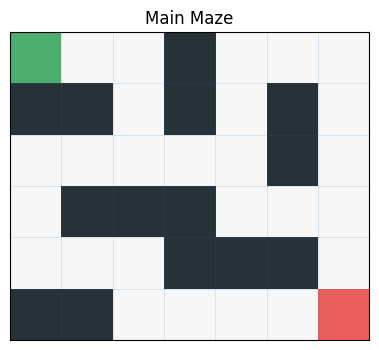

In [5]:
maze = load_maze_csv('data/maze_main.csv')

start = find_marker(maze, 'S')
goal = find_marker(maze, 'G')

print('Start:', start)
print('Goal:', goal)
draw_maze(maze, [], [], 'Main Maze')


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h3 style="text-align:right;color:inherit;">همسایه‌های یک State و بازسازی مسیر</h3>

<p><code>get_neighbors</code> جواب این سؤال را می‌دهد: <strong>«از خانهٔ فعلی به کدام خانه‌ها می‌توانم بروم؟»</strong></p>
<p>برای هر حرکت دو چیز را بررسی می‌کنیم: از محدودهٔ ماز بیرون نرفته باشیم و خانه دیوار نباشد.</p>

<p><code>reconstruct_path</code> کار دیگری دارد. هنگام جست‌وجو برای هر خانه ذخیره می‌کنیم از کجا به آن رسیده‌ایم:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">parent[child] = previous_state</pre>
<p>پس از رسیدن به Goal، با دنبال‌کردن Parentها به Start برمی‌گردیم و مسیر را برعکس می‌کنیم.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">ورودی و خروجی دو تابع مهم</h3>

<p><code>get_neighbors(maze, state)</code></p>
<ul>
<li><strong>ورودی:</strong> خود ماز + State فعلی.</li>
<li><strong>خروجی:</strong> لیست خانه‌های مجازی که از State فعلی می‌توان به آن‌ها رفت.</li>
</ul>

<p><code>reconstruct_path(parent, start, goal)</code></p>
<ul>
<li><strong>ورودی:</strong> Dictionary مربوط به Parent + نقطهٔ شروع + هدف.</li>
<li><strong>خروجی:</strong> مسیر کامل از Start تا Goal.</li>
</ul>

<p>این دو تابع در چند الگوریتم دوباره استفاده می‌شوند؛ پس فهمشان ارزش زیادی دارد.</p>

</div>
</div>

In [ ]:
def get_neighbors(maze, state):
    # TODO: Return valid four-direction neighbors.
    r, c = state
    rows = len(maze)
    cols = len(maze[0])

    # print(maze)
    candidates = [
        (r - 1, c),
        (r, c + 1),
        (r + 1, c),
        (r, c - 1)
    ]
    neighbors = []

    for nr, nc in candidates:
        inside_rows = 0 <= nr and nr < rows
        inside_cols = 0 <= nc and nc < cols

        if inside_rows and inside_cols:
            if maze[nr][nc] != '#':
                neighbors.append((nr, nc))

    return neighbors
    # Write your code here.

    return neighbors


def reconstruct_path(parent, start, goal):
    # TODO: Reconstruct the path from goal to start.
    if start == goal:
        return [start]
    if goal not in parent:
        return []

    path = [goal]
    current = goal


    while current != start:
        current = parent[current]
        path.append(current)

    path.reverse()
    # Write your code here.
    return path


test_neighbors = get_neighbors(maze, start)

if test_neighbors == []:
    print('TODO: complete get_neighbors')
else:
    print('Neighbors of start:', test_neighbors)

sample_parent = {}
sample_parent[(0, 1)] = (0, 0)
sample_parent[(0, 2)] = (0, 1)

sample_path = reconstruct_path(sample_parent, (0, 0), (0, 2))

if sample_path == []:
    print('TODO: complete reconstruct_path')
else:
    print('Sample path:', sample_path)


Neighbors of start: [(0, 1)]
Sample path: [(0, 0), (0, 1), (0, 2)]


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۳: Stack و Queue با همان List</h2>

<p>برای دیدن تفاوت رفتاری Stack و Queue، هر دو را ابتدا با یک <code>list</code> ساده می‌سازیم.</p>

<h3 style="text-align:right;color:inherit;">Stack — LIFO</h3>
<p>مثل یک دسته بشقاب: <strong>آخرین چیزی که وارد شده، اولین چیزی است که خارج می‌شود.</strong></p>
<pre style="direction:ltr;text-align:left;color:inherit;">append(...)  -> add to the end
pop()        -> remove from the end</pre>

<h3 style="text-align:right;color:inherit;">Queue — FIFO</h3>
<p>مثل صف: <strong>اولین چیزی که وارد شده، اولین چیزی است که خارج می‌شود.</strong></p>
<pre style="direction:ltr;text-align:left;color:inherit;">append(...)  -> add to the end
pop(0)       -> remove from the beginning</pre>

<p>برای مازهای کوچک این پیاده‌سازی آموزشی کاملاً کافی است. هدف فعلاً فهم تفاوت رفتار Stack و Queue است.</p>

</div>

In [9]:
stack = []
stack.append('A')
stack.append('B')
stack.append('C')

print('Stack removes:', stack.pop())


queue = []
queue.append('A')
queue.append('B')
queue.append('C')

print('Queue removes:', queue.pop(0))


Stack removes: C
Queue removes: A


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۴: Depth-First Search — DFS</h2>

<p>DFS از Frontier به شکل <strong>Stack</strong> استفاده می‌کند. بنابراین معمولاً یک مسیر را تا جای ممکن عمیق ادامه می‌دهد و بعد برمی‌گردد.</p>

<p>ساختار ذهنی DFS:</p>
<ol>
<li>Start را داخل Frontier بگذار.</li>
<li>آخرین State را از Frontier بردار.</li>
<li>اگر Goal بود، مسیر را بساز.</li>
<li>همسایه‌های جدید را پیدا کن.</li>
<li>Parent آن‌ها را ثبت کن و داخل Frontier بگذار.</li>
</ol>

<p><strong>نکته:</strong> DFS در گراف بدون وزن کوتاه‌ترین مسیر را تضمین نمی‌کند.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
            background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 DFS را خیلی ساده بفهمیم</h3>

<p>فرض کن وارد یک هزارتو شده‌ای و تصمیم می‌گیری:</p>
<p style="text-align:center;"><strong>«هر راهی را که تازه پیدا کردم، تا جایی که می‌شود ادامه می‌دهم.»</strong></p>

<p>DFS دقیقاً همین کار را می‌کند. برای این رفتار از <strong>Stack</strong> استفاده می‌کنیم؛ یعنی آخرین Stateای که وارد Frontier شده، زودتر بررسی می‌شود.</p>

<pre style="direction:ltr;text-align:left;color:inherit;">
        S
      /   \
     A     B
    / \   / \
   C   D E   F
</pre>

<p>اگر از چپ شروع کنیم، DFS می‌تواند این مسیر را دنبال کند:</p>

<pre style="direction:ltr;text-align:left;color:inherit;">
S -> A -> C
</pre>

<p>اگر C راهی نداشت، برمی‌گردد و D را بررسی می‌کند، بعد سراغ شاخهٔ B می‌رود.</p>

<p>یعنی DFS بیشتر شبیه این است:</p>
<p style="text-align:center;"><strong>«یک راه را تا ته برو، بعد برگرد.»</strong></p>

<p><strong>چرا Stack؟</strong><br>
چون می‌خواهیم آخرین مسیری که تازه واردش شده‌ایم، همان لحظه ادامه پیدا کند.</p>

<pre style="direction:ltr;text-align:left;color:inherit;">
Frontier = [A, B, C]

Stack -> next = C
</pre>

<p><strong>نکته:</strong> DFS الزاماً کوتاه‌ترین مسیر را پیدا نمی‌کند؛ ممکن است یک شاخهٔ طولانی را قبل از یک جواب نزدیک بررسی کند.</p>

<p><strong>جملهٔ خیلی ساده:</strong><br>
«DFS یعنی یک کوچه را تا ته برو؛ اگر بسته بود، برگرد.»</p>

</div>
</div>

DFS
found = True
path length = 15
expanded = 16
time = 0.1271 ms


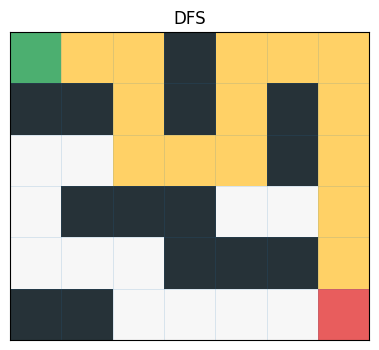

In [ ]:
def dfs_search(maze, start, goal):
    # TODO: Implement DFS with a list used as a stack.
    frontier = [start]
    parent = {}
    discovered = {start}
    visited_order = []

    while frontier:
        state = frontier.pop()
        visited_order.append(state)
        if state == goal:
            path = reconstruct_path(parent, start, goal)
            return make_result(
                True,
                path,
                len(visited_order),
                visited_order,
                'success'
            )          
        
        neighbors = get_neighbors(maze, state)
        # neighbors = neighbors.reverse()
        for i in range(len(neighbors) - 1, -1, -1):
            next_state = neighbors[i]
            if next_state not in discovered:
                discovered.add(next_state)
                parent[next_state] = state
                frontier.append(next_state)

    return make_result(
        False,
        [],
        len(visited_order),
        visited_order,
        'failure'
    )



    # Write your code here.

    # return None


dfs_result = measure_search(dfs_search, maze, start, goal)

if dfs_result is None:
    print('TODO: complete DFS')
else:
    show_result('DFS', dfs_result, maze)


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۵: Breadth-First Search — BFS</h2>

<p>BFS تقریباً همان اجزای DFS را دارد؛ تفاوت اصلی در Frontier است.</p>

<p>در BFS از <strong>Queue</strong> استفاده می‌کنیم:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">DFS: frontier.pop()
BFS: frontier.pop(0)</pre>

<p>به همین دلیل BFS لایه‌به‌لایه جلو می‌رود. وقتی همهٔ حرکت‌ها هزینهٔ برابر دارند، اولین بار که BFS به Goal برسد، مسیر کمترین تعداد یال را دارد.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
            background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 BFS را خیلی ساده بفهمیم</h3>

<p>حالا فرض کن نمی‌خواهی یک مسیر را تا ته بروی. می‌گویی:</p>
<p style="text-align:center;"><strong>«اول همهٔ جاهای یک قدمی را بررسی می‌کنم، بعد همهٔ جاهای دو قدمی را، بعد سه قدمی...»</strong></p>

<p>BFS دقیقاً همین رفتار را دارد. برای این کار از <strong>Queue</strong> استفاده می‌کنیم؛ یعنی Stateای که زودتر وارد Frontier شده، زودتر بررسی می‌شود.</p>

<pre style="direction:ltr;text-align:left;color:inherit;">
        S
      /   \
     A     B
    / \   / \
   C   D E   F
</pre>

<p>BFS این درخت را لایه‌به‌لایه می‌بیند:</p>

<pre style="direction:ltr;text-align:left;color:inherit;">
Level 0: S
Level 1: A, B
Level 2: C, D, E, F
</pre>

<p>یعنی قبل از اینکه وارد عمق ۲ شود، همهٔ Stateهای عمق ۱ را تمام می‌کند.</p>

<p><strong>چرا Queue؟</strong><br>
چون Stateهای قدیمی‌تر باید زودتر بررسی شوند؛ این کار باعث می‌شود ترتیب لایه‌ها حفظ شود.</p>

<pre style="direction:ltr;text-align:left;color:inherit;">
Frontier = [A, B, C]

Queue -> next = A
</pre>

<p>وقتی همهٔ حرکت‌ها هزینهٔ برابر داشته باشند، BFS اولین بار که به Goal می‌رسد، کوتاه‌ترین مسیر از نظر تعداد حرکت را پیدا کرده است.</p>

<p><strong>جملهٔ خیلی ساده:</strong><br>
«BFS یعنی اول همهٔ جاهای نزدیک را بگرد، بعد برو سراغ دورترها.»</p>

</div>
</div>

BFS
found = True
path length = 11
expanded = 24
time = 0.1697 ms


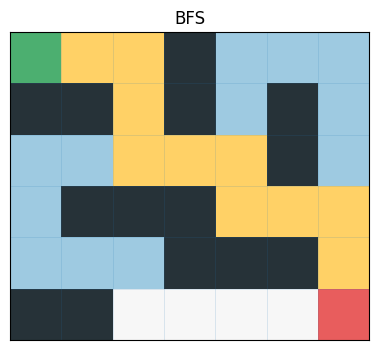

DFS path length = 15
BFS path length = 11


In [ ]:
def bfs_search(maze, start, goal):
    frontier = [start]
    discovered = {start}
    parent = {}
    visited_order = []
    while frontier:
        state = frontier.pop(0)
        visited_order.append(state)

        if state == goal:
            path = reconstruct_path(parent, start, goal)
            return make_result(
                True,
                path,
                len(visited_order),
                visited_order,
                'success'
            )

        neighbors = get_neighbors(maze, state)

        for next_state in neighbors:
            if next_state not in discovered:
                discovered.add(next_state)
                parent[next_state] = state
                frontier.append(next_state)
    return make_result(
        False,
        [],
        len(visited_order),
        visited_order,
        'failure'
    )
s

bfs_result = measure_search(bfs_search, maze, start, goal)

if bfs_result is None:
    print('TODO: complete BFS')
else:
    show_result('BFS', bfs_result, maze)

    if dfs_result is not None:
        print('DFS path length =', dfs_result['path_length'])
        print('BFS path length =', bfs_result['path_length'])


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۶: DLS و IDS</h2>

<h3 style="text-align:right;color:inherit;">Depth-Limited Search — DLS</h3>
<p>DLS همان ایدهٔ DFS را دارد، اما اجازه نمی‌دهیم از یک عمق مشخص پایین‌تر برود.</p>

<p>سه حالت مهم:</p>
<ul>
<li><strong>success:</strong> هدف پیدا شده است.</li>
<li><strong>failure:</strong> جست‌وجو تمام شده و جوابی در این مسیر وجود ندارد.</li>
<li><strong>cutoff:</strong> به محدودیت عمق خورده‌ایم؛ شاید جواب در عمق بیشتر باشد.</li>
</ul>

<h3 style="text-align:right;color:inherit;">Iterative Deepening Search — IDS</h3>
<p>به‌جای حدس‌زدن یک Limit بزرگ، DLS را چند بار اجرا می‌کنیم:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">limit = 0
limit = 1
limit = 2
limit = 3
...</pre>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 DLS را خیلی ساده بفهمیم</h3>

<p>فرض کن داری در یک ساختمان دنبال اتاق هدف می‌گردی، ولی به تو گفته‌اند: <strong>«بیشتر از ۲ طبقه پایین نرو.»</strong></p>
<pre style="direction:ltr;text-align:left;color:inherit;">        S        depth 0
       / \
      A   B      depth 1
     /     \
    C       D    depth 2
   /
  G              depth 3</pre>
<p>اگر <code>limit = 2</code> باشد، جست‌وجو به C می‌رسد ولی اجازه ندارد وارد G شود.</p>
<p>پس اینجا نمی‌گوییم Goal وجود ندارد؛ می‌گوییم <strong>cutoff</strong> اتفاق افتاده، یعنی محدودیت عمق جلوی ادامه را گرفته است.</p>
<ul><li><strong>success:</strong> Goal پیدا شد.</li><li><strong>failure:</strong> راه تمام شد و جواب نبود.</li><li><strong>cutoff:</strong> شاید جواب پایین‌تر باشد ولی Limit اجازه نداد.</li></ul>
<p> DLS یعنی «DFS با ترمز عمق».</p>
</div></div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 IDS را خیلی ساده بفهمیم</h3>

<p>مشکل DLS این بود که باید از قبل Limit را حدس بزنیم. IDS می‌گوید اصلاً حدس نزن؛ از صفر شروع کن و هر بار یکی زیادش کن.</p>
<pre style="direction:ltr;text-align:left;color:inherit;">DLS(limit=0)  -> cutoff
DLS(limit=1)  -> cutoff
DLS(limit=2)  -> cutoff
DLS(limit=3)  -> success</pre>
<p>اگر Goal در عمق ۳ باشد، دفعهٔ چهارم پیدایش می‌کنیم.</p>
<p>IDS بخش‌های بالای درخت را چند بار می‌بیند، اما لازم نیست مثل BFS یک Frontier بزرگ را هم‌زمان نگه دارد.</p>
<p><strong>مثال انسانی:</strong> هر بار طناب جست‌وجویت را یک متر بلندتر کن.</p>
<p> IDS یعنی «DFSهای محدود، با Limitهای ۰، ۱، ۲، ۳، ...».</p>
</div></div>

DLS
found = False
path length = None
expanded = 0
DLS with limit 3: cutoff
IDS
found = True
path length = 11
expanded = 0
time = 0.9959 ms


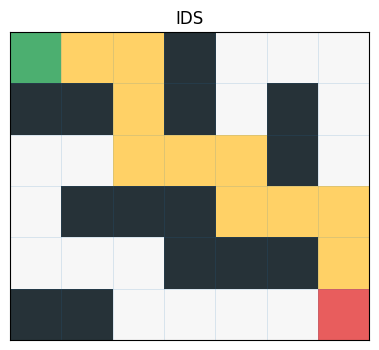

In [29]:
def depth_limited_search(maze, start, goal, limit):
    frontier = [(start, 0, [start])]
    visited_order = []
    cutoff_happened = False

    while frontier:
        state, depth, path = frontier.pop()
        if state == goal:
            return make_result(
                True,
                path,
                len(visited_order),
                visited_order,
                'success'
            )
        neighbors = get_neighbors(maze, state)

        if depth == limit:
            for next_state in neighbors:
                if next_state not in path:         
                    cutoff_happened = True
                    break
            continue

        
        for i in range(len(neighbors) - 1, -1, -1):
            next_state = neighbors[i]
            if next_state not in path:
                new_path = path + [next_state]
                frontier.append((next_state,depth + 1 , new_path))
    
    if cutoff_happened:
        status = 'cutoff'
    else:
        status = 'failure'
    return make_result(
        False,
        [],
        len(visited_order),
        visited_order,
        status
    )

    # Write your code here.

def iterative_deepening_search(maze, start, goal):
    # Run DLS with limits 0, 1, 2, ...
    depth = 0

    while True:
        result = depth_limited_search(maze, start, goal, depth)

        if result['status'] == 'success':
            return result
        if result['status'] == 'failure':
            return result

        depth += 1

small_dls = depth_limited_search(maze, start, goal, 7)
show_result('DLS', small_dls, maze)

if small_dls is None:
    print('TODO: complete DLS')
else:
    print('DLS with limit 3:', small_dls['status'])

ids_result = measure_search(iterative_deepening_search, maze, start, goal)

if ids_result is None:
    print('TODO: complete IDS')
else:
    show_result('IDS', ids_result, maze)


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۷: Priority Queue و UCS</h2>

<p>تا اینجا ترتیب ورود تعیین می‌کرد چه Stateای زودتر بررسی شود. حالا می‌خواهیم هر State یک <strong>Priority</strong> داشته باشد.</p>

<p>برای اینکه سازوکار Priority Queue کاملاً قابل مشاهده باشد، ابتدا آن را با یک List ساده پیاده‌سازی می‌کنیم. هر عضو به شکل زیر است:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">(priority, state)</pre>

<p>تابع <code>pop_smallest</code> داخل List می‌گردد، کوچک‌ترین Priority را پیدا می‌کند و همان عضو را خارج می‌کند.</p>

<p><strong>این روش برای آموزش است، نه برای ورودی‌های بزرگ.</strong> فعلاً هدف فهم رفتار Priority Queue است.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تابع pop_smallest را باید بفهمیم</h3>

<p><code>pop_smallest(frontier)</code> از میان اعضای Frontier، موردی را پیدا می‌کند که عدد Priority کوچک‌تری دارد و همان را خارج می‌کند.</p>

<pre style="direction:ltr;text-align:left;color:inherit;">[(7, 'B'), (2, 'C'), (5, 'D')]
              ↓
          (2, 'C')</pre>

<p>بعداً معنای Priority تغییر می‌کند:</p>
<ul>
<li>UCS: مقدار <code>g(n)</code></li>
<li>Greedy: مقدار <code>h(n)</code></li>
<li>A*: مقدار <code>g(n) + h(n)</code></li>
</ul>

</div>
</div>

In [30]:
def pop_smallest(frontier):
    # TODO: Remove and return the item with the smallest priority.

    best_index = 0

    for i in range(1, len(frontier)):
        if frontier[i][0] < frontier[best_index][0]:
            best_index = i

    return frontier.pop(best_index)


priority_demo = [(7, 'B'), (2, 'C'), (5, 'D')]
priority_result = pop_smallest(priority_demo)

if priority_result is None:
    print('TODO: complete pop_smallest')
else:
    print('Priority Queue removes:', priority_result)


Priority Queue removes: (2, 'C')


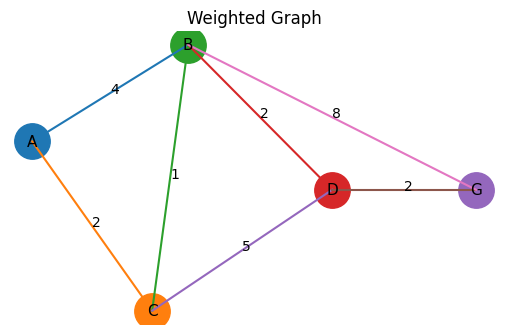

In [31]:
weighted_data = load_weighted_graph_json('data/weighted_graph.json')

weighted_edges = weighted_data['edges']
weighted_positions = weighted_data['positions']
weighted_graph = {}

for edge in weighted_edges:
    u = edge[0]
    v = edge[1]
    weight = edge[2]
    if u not in weighted_graph:
        weighted_graph[u] = []
    if v not in weighted_graph:
        weighted_graph[v] = []
    weighted_graph[u].append((v, weight))
    weighted_graph[v].append((u, weight))

draw_weighted_graph(weighted_edges, weighted_positions, 'Weighted Graph')


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h3 style="text-align:right;color:inherit;">Uniform Cost Search — UCS</h3>

<p>در گراف وزن‌دار، کمترین تعداد یال الزاماً کمترین هزینه نیست.</p>
<p>UCS همیشه Stateای را انتخاب می‌کند که <code>g(n)</code> کوچک‌تری دارد:</p>

<p style="text-align:center;"><strong><code>g(n) = هزینهٔ واقعی از Start تا n</code></strong></p>

<p>اگر همهٔ یال‌ها هزینهٔ یکسان داشته باشند، رفتار UCS از نظر انتخاب مسیر به BFS نزدیک می‌شود.</p>

</div>

In [33]:
def uniform_cost_search(graph, start, goal):
    # TODO: Implement Uniform Cost Search.
    frontier = [(0, start)]
    best_cost = {start: 0}
    parent = {}
    visited_order = []
    
    while frontier:
        item = pop_smallest(frontier)
        cost = item[0]
        state = item[1]
        
        if cost != best_cost[state]:
            continue
        
        visited_order.append(state)

        if state == goal:
            path = reconstruct_path(parent, start, goal)
            result = make_result(
                True,
                path,
                len(visited_order),
                visited_order,
                'success'
            )
            result['cost'] = cost
            return result

        for next_state, weight in graph[state]:
            new_cost = cost + weight
            better_path = False
            if next_state not in best_cost:
                better_path = True
            else:
                if new_cost < best_cost[next_state]:
                    better_path = True

            if better_path:
                best_cost[next_state] = new_cost
                parent[next_state] = state
                frontier.append((new_cost, next_state))
            
    result = make_result(
        False,
        [],
        len(visited_order),
        visited_order,
        'failure'
    )
    result['cost'] = None
    return result
    

    # Write your code here.

    return None


ucs_result = measure_search(uniform_cost_search, weighted_graph, 'A', 'G')

if ucs_result is None:
    print('TODO: complete UCS')
else:
    print('UCS path =', ucs_result['path'])
    print('UCS total cost =', ucs_result['cost'])


UCS path = ['A', 'C', 'B', 'D', 'G']
UCS total cost = 7


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۸: Heuristic</h2>

<p>روش‌های قبلی جهت Goal را نمی‌دانستند. <strong>Heuristic</strong> یک تخمین از فاصلهٔ State فعلی تا Goal است:</p>

<p style="text-align:center;"><strong><code>h(n) = تخمین هزینهٔ باقی‌مانده تا Goal</code></strong></p>

<p>برای حرکت چهارجهته، فاصلهٔ Manhattan طبیعی است:</p>

$$
h_{\text{Manhattan}} =
|r_1-r_2| + |c_1-c_2|
$$

<p>برای مقایسه، فاصلهٔ Euclidean:</p>

$$
h_{\text{Euclidean}} =
\sqrt{(r_1-r_2)^2 + (c_1-c_2)^2}
$$

<p>در این جلسه Heuristic را به‌عنوان «راهنمای جست‌وجو» می‌بینیم، نه به‌عنوان جواب نهایی.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">تابع‌های فاصله چه ورودی و خروجی‌ای دارند؟</h3>

<p><code>manhattan_distance(a, b)</code> دو مختصات را می‌گیرد و یک عدد برمی‌گرداند که برای ما Heuristic اصلی است.</p>

<pre style="direction:ltr;text-align:left;color:inherit;">a = (1, 2)
b = (4, 6)

Manhattan = 7</pre>

<p><code>euclidean_distance(a, b)</code> هم یک عدد فاصله می‌دهد، اما اینجا بیشتر برای مقایسه است. در Greedy و A* این نوت‌بوک از Manhattan استفاده می‌کنیم.</p>

</div>
</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 Heuristic را با یک مثال بفهمیم</h3>

<p>Heuristic یک <strong>تخمین</strong> است؛ مثل قطب‌نما که می‌گوید Goal تقریباً کدام سمت و چقدر دور است.</p>
<p>اگر:</p><pre style="direction:ltr;text-align:left;color:inherit;">A = (1, 2)
G = (4, 6)</pre>
<p>برای Manhattan:</p><pre style="direction:ltr;text-align:left;color:inherit;">row difference    = 3
column difference = 4
h = 3 + 4 = 7</pre>
<p>یعنی اگر فقط بالا/پایین/چپ/راست حرکت کنیم و دیواری نباشد، حداقل ۷ حرکت جهت‌دار لازم است.</p>
<p><strong>نکته:</strong> Heuristic مسیر واقعی را نمی‌داند؛ فقط تخمین می‌زند.</p>
<p> Heuristic نقشه نیست؛ قطب‌نماست.</p>
</div></div>

In [34]:
def manhattan_distance(a, b):
    # Compute Manhattan distance.
    row_distance = abs(a[0] - b[0])
    column_distance = abs(a[1] - b[1])
    return row_distance + column_distance


def euclidean_distance(a, b):
    # Compute Euclidean distance.
    row_distance = a[0] - b[0]
    column_distance = a[1] - b[1]
    squared_distance = row_distance ** 2 + column_distance ** 2
    return squared_distance ** 0.5


point_a = (1, 2)
point_b = (5, 5)

print('Manhattan =', manhattan_distance(point_a, point_b))
print('Euclidean =', euclidean_distance(point_a, point_b))


Manhattan = 7
Euclidean = 5.0


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۹: Greedy Best-First Search</h2>

<p>Greedy فقط به Heuristic نگاه می‌کند:</p>
<p style="text-align:center;"><strong><code>Priority = h(n)</code></strong></p>

<p>یعنی هر بار Stateای را زودتر بررسی می‌کند که <strong>ظاهراً</strong> به Goal نزدیک‌تر است.</p>
<p>این روش می‌تواند سریع باشد، اما نزدیک‌تر بودن ظاهری همیشه به معنی مسیر بهتر نیست؛ ممکن است دیوار یا مانع جلوی آن باشد.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 Greedy را خیلی ساده بفهمیم</h3>

<p>Greedy فقط یک سؤال می‌پرسد: <strong>«کدام State همین الان به Goal نزدیک‌تر به نظر می‌رسد؟»</strong></p>
<pre style="direction:ltr;text-align:left;color:inherit;">S . . . # G
      ↑
  looks close</pre>
<p>ممکن است Greedy مستقیم به سمت Goal برود، ولی یک دیوار جلویش باشد و مجبور شود دور بزند.</p>
<p>Greedy فقط <code>h(n)</code> را می‌بیند؛ یعنی گذشته و هزینه‌ای که تا الان داده‌ایم برایش مهم نیست.</p>
<ul><li>می‌تواند خیلی سریع باشد.</li><li>اما بهترین مسیر را تضمین نمی‌کند.</li></ul>
<p><strong>مثال انسانی:</strong> در شهر فقط به فاصلهٔ هوایی مقصد نگاه کنی، بدون توجه به خیابان بسته و پل و دوربرگردان.</p>
<p> Greedy هر بار ظاهراً نزدیک‌ترین گزینه به Goal را برمی‌دارد.</p>
</div></div>

In [14]:
def greedy_best_first_search(maze, start, goal):
    # TODO: Implement Greedy Best-First Search.

    # Write your code here.

    return None


greedy_result = measure_search(greedy_best_first_search, maze, start, goal)

if greedy_result is None:
    print('TODO: complete Greedy Search')
else:
    show_result('Greedy', greedy_result, maze)


TODO: complete Greedy Search


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۱۰: A*</h2>

<p>A* دو نوع اطلاعات را با هم استفاده می‌کند:</p>

<ul>
<li><code>g(n)</code>: هزینهٔ واقعی طی‌شده از Start تا State فعلی.</li>
<li><code>h(n)</code>: تخمین فاصلهٔ باقی‌مانده تا Goal.</li>
</ul>

$$
f(n) = g(n) + h(n)
$$

<p>پس:</p>
<pre style="direction:ltr;text-align:left;color:inherit;">UCS    -> g(n)
Greedy -> h(n)
A*     -> g(n) + h(n)</pre>

<p><code>g_score[state]</code> بهترین هزینه‌ای است که تا این لحظه برای رسیدن به آن State پیدا کرده‌ایم. اگر بعداً مسیر ارزان‌تری پیدا شود، Parent و g_score را به‌روز می‌کنیم.</p>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">
<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;background:rgba(37,99,235,0.07);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin-top:0;text-align:right;color:inherit;">🧠 A* را خیلی ساده بفهمیم</h3>

<p>UCS فقط گذشته را می‌بیند: <code>g(n)</code> یعنی تا اینجا چقدر هزینه کرده‌ایم.</p>
<p>Greedy فقط آینده را حدس می‌زند: <code>h(n)</code> یعنی تقریباً چقدر تا Goal مانده.</p>
<p>A* هر دو را با هم می‌بیند:</p>
<p style="text-align:center;font-size:1.1em;"><strong><code>f(n) = g(n) + h(n)</code></strong></p>
<pre style="direction:ltr;text-align:left;color:inherit;">State A: g=2 , h=7 -> f=9
State B: g=5 , h=2 -> f=7

A* chooses B</pre>
<p>چرا B؟ چون مجموع هزینهٔ طی‌شده و تخمین باقی‌مانده کمتر است.</p>
<p><strong>مثال انسانی:</strong> برای انتخاب مسیر سفر هم می‌پرسی «تا اینجا چقدر آمده‌ام؟» و هم «چقدر دیگر مانده؟».</p>
<p> A* هم گذشته را حساب می‌کند، هم آینده را حدس می‌زند.</p>
</div></div>

In [15]:
def a_star_search(maze, start, goal):
    # TODO: Implement A* Search.

    # Write your code here.

    return None


astar_result = measure_search(a_star_search, maze, start, goal)

if astar_result is None:
    print('TODO: complete A*')
else:
    show_result('A*', astar_result, maze)

    if bfs_result is not None:
        print('BFS path length =', bfs_result['path_length'])
        print('A* path length =', astar_result['path_length'])


TODO: complete A*


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۱۱: مقایسهٔ نهایی روی یک ماز جدید</h2>

<p>حالا الگوریتم‌ها را روی مازی اجرا می‌کنیم که در مثال اصلی نبود.</p>

<p>سه معیار ساده را مقایسه می‌کنیم:</p>
<ul>
<li><strong>Path Length:</strong> طول مسیر نهایی.</li>
<li><strong>Expanded:</strong> چند State واقعاً بررسی شده است.</li>
</ul>

<p>هدف این بخش این است که نتیجه بگیریم «بهترین الگوریتم» بدون توجه به نوع مسئله معنی ندارد.</p>

</div>

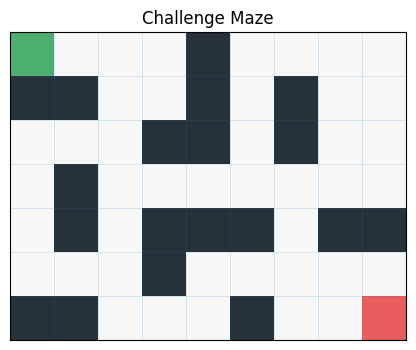

In [16]:
challenge_maze = load_maze_csv('data/maze_challenge.csv')

challenge_start = find_marker(challenge_maze, 'S')
challenge_goal = find_marker(challenge_maze, 'G')

draw_maze(challenge_maze, [], [], 'Challenge Maze')


In [17]:
comparison = []

if dfs_result is not None:
    result = measure_search(dfs_search, challenge_maze, challenge_start, challenge_goal)
    comparison.append(('DFS', result))

if bfs_result is not None:
    result = measure_search(bfs_search, challenge_maze, challenge_start, challenge_goal)
    comparison.append(('BFS', result))

if ids_result is not None:
    result = measure_search(iterative_deepening_search, challenge_maze, challenge_start, challenge_goal)
    comparison.append(('IDS', result))

if greedy_result is not None:
    result = measure_search(greedy_best_first_search, challenge_maze, challenge_start, challenge_goal)
    comparison.append(('Greedy', result))

if astar_result is not None:
    result = measure_search(a_star_search, challenge_maze, challenge_start, challenge_goal)
    comparison.append(('A*', result))

if comparison == []:
    print('Complete the search algorithms to see the final comparison.')
else:
    show_comparison_table(comparison)


Complete the search algorithms to see the final comparison.


<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<h2 style="text-align:right;color:inherit;">بخش ۱۲: سؤال‌های جمع‌بندی</h2>

<ol>
<li>تفاوت Frontier و Discovered چیست؟</li>
<li>چرا DFS از Stack و BFS از Queue استفاده می‌کند؟</li>
<li>چرا BFS در گراف بدون وزن کوتاه‌ترین مسیر را پیدا می‌کند؟</li>
<li>تفاوت <code>failure</code> و <code>cutoff</code> در DLS چیست؟</li>
<li>در UCS، Greedy و A* چه چیزی Priority را تعیین می‌کند؟</li>
<li>اگر در A* مقدار <code>h(n)=0</code> باشد، رفتار الگوریتم به کدام روش نزدیک می‌شود؟</li>
<li>چرا Greedy ممکن است سریع باشد ولی مسیر بهینه ندهد؟</li>
<li>چرا <code>Parent</code> را ذخیره می‌کنیم؟</li>
</ol>

</div>

<div dir="rtl" lang="fa" style="direction:rtl;text-align:right;line-height:2;color:inherit;">

<div style="border:1px solid rgba(148,163,184,0.35);border-right:5px solid #2563eb;
            background:rgba(37,99,235,0.06);padding:14px 18px;border-radius:8px;margin:10px 0;color:inherit;">
<h3 style="margin:0 0 8px 0;text-align:right;color:inherit;">پاسخ شما</h3>
<p>پاسخ‌های تحلیلی خود را اینجا یا در یک سلول Markdown جدید بنویسید.</p>
</div>

</div>